# Lab 08 — Build a vision-language model, then open a real one

**Book sections:** [5.1 The LLaVA recipe](../../book/docs/chapters/05-vlms/recipe.md),
[5.2 Training VLMs](../../book/docs/chapters/05-vlms/training.md),
[5.3 Modern small VLMs](../../book/docs/chapters/05-vlms/small-vlms.md),
[5.4 Grounding, spatial reasoning and hallucination](../../book/docs/chapters/05-vlms/spatial.md).

**Goal.** Assemble a LLaVA-style VLM from parts you have built — the tiny CLIP image tower (Lab 07), an MLP
projector, and TinyGPT (Lab 04) — and train it in the two classic stages: projector-only alignment on
captions, then visual instruction tuning on questions and answers. Watch which skills it learns first, find
out why location comes last and speed it up with 2-D positions, look at where it attends, catch it
hallucinating, and then dissect SmolVLM-256M: its image tokens, pixel shuffle and image splitting.

**Runtime:** ≈12 min with a GPU, ≈1.5 h on CPU. **Downloads:** ≈510 MB (SmolVLM-256M-Instruct).
**GPU:** optional (≈1.5 GB in bf16). **Seed:** 0. **Reads** `data/checkpoints/tiny_clip.pt` from Lab 07
(trains a replacement if it is missing).

In [1]:
import os
import random
import time
from collections import defaultdict
from pathlib import Path

os.environ.setdefault("HF_HOME", str(Path("../../data/hf").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from vlacourse.clip import TinyCLIP, clip_loss
from vlacourse.data import scenes
from vlacourse.seed import device, set_seed
from vlacourse.transformer import TinyGPT
from vlacourse.vision import to_tensor
from vlacourse.vlm import TinyVLM

set_seed(0)
dev = device()
V = len(scenes.VOCAB)
print("device:", dev)

device: cuda


## 1. Data: captions and visual questions
Same scenes as Lab 07. Every scene yields a caption and several question–answer pairs (colour, object,
count, location, relation). Test questions come from scenes never seen in training.

In [2]:
N_TRAIN, N_TEST = 11_000, 1_000
sc, im = scenes.scene_dataset(N_TRAIN + N_TEST, seed=0)
X = to_tensor(im)
caps = [scenes.caption(s) for s in sc]
qa = [(i, q, a) for i, s in enumerate(sc) for q, a in scenes.qa_pairs(s)]
train_qa = [x for x in qa if x[0] < N_TRAIN]
test_qa = [x for x in qa if x[0] >= N_TRAIN]


def qtype(q):
    if q.startswith("what color"):
        return "colour"
    if q.startswith("how many"):
        return "count"
    if q.startswith("where"):
        return "location"
    return "relation" if any(r in q for r in ("left of", "right of", "above", "below")) else "object"


print(len(train_qa), "training and", len(test_qa), "test questions")
for x in random.Random(0).sample(test_qa, 5):
    print(f"  [{qtype(x[1]):8}] {x[1]!r:38} -> {x[2]!r}")

73117 training and 6636 test questions
  [count   ] 'how many objects are there?'          -> 'two'
  [location] 'where is the red toolbox?'            -> 'center'
  [location] 'where is the blue crate?'             -> 'center'
  [colour  ] 'what color is the toolbox?'           -> 'blue'
  [colour  ] 'what color is the cone?'              -> 'red'


## 2. The parts
**Vision tower:** the image encoder of the tiny CLIP from Lab 07, frozen. **Language model:** a TinyGPT
pretrained on *text only* — captions and question/answer strings — so it knows the language of the depot
but has never seen an image.

In [3]:
CKPT = Path("../../data/checkpoints/tiny_clip.pt")
clip = TinyCLIP(V).to(dev)
if CKPT.exists():
    clip.load_state_dict(torch.load(CKPT, map_location=dev))
    print("loaded", CKPT)
else:                                                       # same recipe as Lab 07, shorter
    seqs = [scenes.encode(c) + [scenes.EOS] for c in caps]
    ids = torch.full((len(seqs), 12), scenes.PAD)
    for i, s_ in enumerate(seqs):
        ids[i, :len(s_)] = torch.tensor(s_)
    eos = torch.tensor([len(s_) - 1 for s_ in seqs])
    opt = torch.optim.AdamW(clip.parameters(), 1e-3, weight_decay=0.05)
    for step in range(1000):
        j = torch.randint(0, N_TRAIN, (256,))
        loss = clip_loss(clip.encode_image(X[j].to(dev)), clip.encode_text(ids[j].to(dev), eos[j].to(dev)), clip.logit_scale)
        opt.zero_grad(); loss.backward(); opt.step()
    print("trained a tiny CLIP, final loss", loss.item())
vision = clip.image_encoder


def pad(seqs, fill=scenes.PAD):
    out = torch.full((len(seqs), max(map(len, seqs))), fill)
    for i, s_ in enumerate(seqs):
        out[i, :len(s_)] = torch.tensor(s_)
    return out


def prompt_ids(q):
    return [scenes.BOS] + scenes.encode(q) + [scenes.SEP]


# TinyGPT uses *learned absolute* positions. In the VLM its text will start at position 64, after the image
# tokens, so we pretrain it with an empty 64-token slot in front (zeros): otherwise positions 64+ would be
# untrained. An LLM with relative positions (RoPE) would not need this.
set_seed(0)
lm = TinyGPT(V, d=128, n_layers=4, n_heads=4, max_len=96).to(dev)
texts = pad([[scenes.BOS] + scenes.encode(c) + [scenes.EOS] for c in caps[:N_TRAIN]]
            + [prompt_ids(q) + scenes.encode(a) + [scenes.EOS] for _, q, a in train_qa]).to(dev)
opt = torch.optim.AdamW(lm.parameters(), lr=1e-3)
for step in range(800):
    b = texts[torch.randint(0, len(texts), (256,))]
    y = b[:, 1:].masked_fill(b[:, 1:] == scenes.PAD, -100)
    blank = torch.zeros(len(b), 64, 128, device=dev)
    loss = F.cross_entropy(lm(b[:, :-1], prefix=blank)[:, 64:].reshape(-1, V), y.reshape(-1), ignore_index=-100)
    opt.zero_grad(); loss.backward(); opt.step()
print(f"text-only LM loss {loss.item():.3f}")
lm_text_only = {k: v.clone() for k, v in lm.state_dict().items()}       # kept for the comparison in §7
lm.eval()
with torch.no_grad():                                      # greedy answer with an empty image slot
    ids_ = torch.tensor([prompt_ids("what color is the toolbox?")], device=dev)
    for _ in range(2):
        nxt = lm(ids_, prefix=torch.zeros(1, 64, 128, device=dev))[:, -1].argmax(-1, keepdim=True)
        ids_ = torch.cat([ids_, nxt], 1)
print("blind LM answers 'what color is the toolbox?' with:", repr(scenes.decode(ids_[0, -2:].tolist())),
      "— a guess from the language prior, since it cannot see")

loaded ../../data/checkpoints/tiny_clip.pt


text-only LM loss 0.621
blind LM answers 'what color is the toolbox?' with: 'blue' — a guess from the language prior, since it cannot see


## 3. Assemble the VLM
64 patch tokens of width 128 from the vision tower → 2-layer MLP projector → 64 *image tokens* in the
LM's embedding space, placed before the text (book 5.1).

In [4]:
set_seed(0)
vlm = TinyVLM(vision, lm, d_vision=128).to(dev)
for name, part in [("vision tower", vlm.vision), ("projector", vlm.projector), ("language model", vlm.lm)]:
    print(f"{name:15} {sum(p.numel() for p in part.parameters()):>9,} parameters")
with torch.no_grad():
    img_tok = vlm.image_tokens(X[:2].to(dev))
    ids_ = pad([prompt_ids("what color is the toolbox?")] * 2).to(dev)
    print("images", tuple(X[:2].shape), "-> image tokens", tuple(img_tok.shape),
          "; text ids", tuple(ids_.shape), "-> logits for text positions", tuple(vlm(X[:2].to(dev), ids_).shape))
    print(f"scale check: image-token rms {img_tok.pow(2).mean().sqrt():.3f}  vs word-embedding rms "
          f"{lm.tok_emb.weight.pow(2).mean().sqrt():.3f}  (the projector must learn to match them)")

vision tower    1,082,880 parameters
projector          33,024 parameters
language model  1,067,392 parameters
images (2, 3, 64, 64) -> image tokens (2, 64, 128) ; text ids (2, 8) -> logits for text positions (2, 8, 42)
scale check: image-token rms 0.199  vs word-embedding rms 0.062  (the projector must learn to match them)


## 4. Training utilities
One function for both stages: build `[image][<bos> prompt <sep> answer <eos>]`, set the targets of the
prompt positions to −100 (loss mask, book 2.5), train only the parameters we pass in.

In [5]:
def batch(items):
    """items: (image index, prompt ids, answer ids) -> images, inputs (B, T), targets (B, T)."""
    seqs = [p + a for _, p, a in items]
    tgts = [[-100] * (len(p) - 1) + a for _, p, a in items]   # predict answer tokens only
    x, y = pad(seqs), pad(tgts, -100)
    return X[[i for i, _, _ in items]].to(dev), x[:, :-1].to(dev), y[:, :x.shape[1] - 1].to(dev)


def fit(items, params, steps, lr, bs=256):
    params = [p for p in params if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.05)
    vlm.train()
    for step in range(steps):
        imgs, x, y = batch(random.sample(items, bs))
        loss = F.cross_entropy(vlm(imgs, x).reshape(-1, V), y.reshape(-1), ignore_index=-100)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    vlm.eval()
    return loss.item()


@torch.no_grad()
def answer(img_idx, questions, n_new=12):
    """Greedy answers; prompts of equal length are batched together."""
    out = [None] * len(questions)
    by_len = defaultdict(list)
    for k, q in enumerate(questions):
        by_len[len(prompt_ids(q))].append(k)
    for ks in by_len.values():
        ids_ = torch.tensor([prompt_ids(questions[k]) for k in ks], device=dev)
        gen = vlm.generate(X[[img_idx[k] for k in ks]].to(dev), ids_, n_new, eos=scenes.EOS)
        for k, g_ in zip(ks, gen):
            out[k] = scenes.decode(g_.tolist())
    return out


def evaluate_qa(items):
    preds = answer([i for i, _, _ in items], [q for _, q, _ in items])
    acc = defaultdict(list)
    for (_, q, a), p in zip(items, preds):
        acc[qtype(q)].append(p == a)
    return {k: round(float(np.mean(v)), 3) for k, v in sorted(acc.items())}


eval_set = random.Random(1).sample(test_qa, 2000)

## 5. Stage 1 — alignment: train only the projector, on captions
Vision tower and LM frozen. The projector learns to produce "words" the frozen LM can read.

In [6]:
cap_items = [(i, [scenes.BOS, scenes.SEP], scenes.encode(caps[i]) + [scenes.EOS]) for i in range(N_TRAIN)]
for p in vlm.vision.parameters():
    p.requires_grad = False
for p in vlm.lm.parameters():
    p.requires_grad = False
t0 = time.time()
print(f"stage 1 loss {fit(cap_items, vlm.projector.parameters(), 600, 1e-3):.3f}  ({time.time() - t0:.0f} s)")
test_idx = list(range(N_TRAIN, N_TRAIN + 500))
pred_caps = answer(test_idx, [""] * len(test_idx), n_new=14)
print("caption exact match on new scenes:", np.mean([p == caps[i] for p, i in zip(pred_caps, test_idx)]))
for i, p in list(zip(test_idx, pred_caps))[:4]:
    print(f"  true {caps[i]!r:50}  generated {p!r}")
print("QA before instruction tuning:", evaluate_qa(eval_set))

stage 1 loss 0.767  (66 s)
caption exact match on new scenes: 0.082
  true 'a yellow barrel below a yellow crate'              generated 'a blue toolbox left of a blue toolbox'
  true 'a yellow cone, a yellow toolbox and a green crate'  generated 'a yellow toolbox, a yellow toolbox and a green toolbox'
  true 'a blue barrel, a blue cone and a green barrel'     generated 'a blue toolbox, a blue toolbox and a blue toolbox'
  true 'a red crate left of a red toolbox'                 generated 'a red toolbox, a red toolbox'


QA before instruction tuning: {'colour': 0.055, 'count': 0.0, 'location': 0.0, 'object': 0.119, 'relation': 0.006}


Projector-only alignment is weak here: captions on new scenes are mostly wrong and questions cannot be
answered at all. A frozen 1 M-parameter LM trained on 42 words has never learned to read *foreign*
tokens; its attention heads only know where words usually sit. LLaVA's stage 1 works with a frozen
7 B LM because a large LM is a far more general in-context reader (book 5.2). Here, stage 1 still
gives stage 2 a projector that produces tokens of the right scale and rough content.

## 6. Stage 2 — visual instruction tuning: projector + LM, on questions
The loss covers only the answer tokens; the vision tower stays frozen, as in LLaVA. We evaluate every 400
steps to see *which skills are learned when*.

In [7]:
qa_items = [(i, prompt_ids(q), scenes.encode(a) + [scenes.EOS]) for i, q, a in train_qa]


def stage2(model_params, steps=2000, lr=5e-4, every=400):
    opt = torch.optim.AdamW([p for p in model_params if p.requires_grad], lr=lr, weight_decay=0.0)
    curve = []
    vlm.train()
    for step in range(1, steps + 1):
        imgs, x, y = batch(random.sample(qa_items, 256))
        loss = F.cross_entropy(vlm(imgs, x).reshape(-1, V), y.reshape(-1), ignore_index=-100)
        opt.zero_grad(); loss.backward(); opt.step()
        if step % every == 0:
            acc = evaluate_qa(eval_set)
            vlm.train()
            curve.append((step, acc))
            print(f"step {step:5d}  loss {loss.item():.3f}  {acc}")
    vlm.eval()
    return curve


for p in vlm.lm.parameters():
    p.requires_grad = True
t0 = time.time()
curve_1d = stage2(list(vlm.projector.parameters()) + list(vlm.lm.parameters()))
print(f"({time.time() - t0:.0f} s)")

step   400  loss 0.477  {'colour': 0.696, 'count': 0.99, 'location': 0.194, 'object': 0.644, 'relation': 0.557}


step   800  loss 0.235  {'colour': 0.898, 'count': 0.99, 'location': 0.372, 'object': 0.87, 'relation': 0.845}


step  1200  loss 0.131  {'colour': 0.945, 'count': 0.977, 'location': 0.719, 'object': 0.926, 'relation': 0.885}


step  1600  loss 0.060  {'colour': 0.965, 'count': 0.997, 'location': 0.819, 'object': 0.961, 'relation': 0.96}


step  2000  loss 0.046  {'colour': 0.971, 'count': 0.997, 'location': 0.839, 'object': 0.974, 'relation': 0.971}
(250 s)


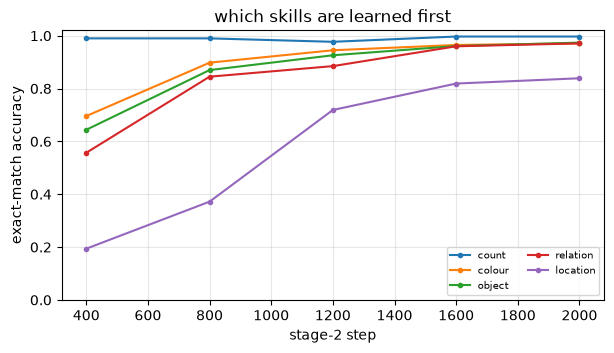

In [8]:
def plot_curves(curves, title):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for (name, curve), ls in zip(curves, ["-", "--"]):
        for k, c in zip(["count", "colour", "object", "relation", "location"], plt.cm.tab10.colors):
            ax.plot([s for s, _ in curve], [a[k] for _, a in curve], ls, color=c, marker="o", ms=3,
                    label=f"{k} ({name})" if len(curves) > 1 else k)
    ax.set_xlabel("stage-2 step"); ax.set_ylabel("exact-match accuracy"); ax.set_ylim(0, 1.02)
    ax.set_title(title); ax.legend(fontsize=7, ncol=2); ax.grid(alpha=0.3)
    plt.show()


plot_curves([("1-D", curve_1d)], "which skills are learned first")

Counting is learned almost immediately, then colour and object identity, then relations. **Location** ("where
is the red toolbox?" → "top left") is learned last. Is the information missing from the frozen vision
tower? A linear probe on its features answers that.

In [9]:
probe_sc, probe_im = scenes.scene_dataset(3000, seed=9, n_objects=1)
regions = sorted({scenes.region(s.objects[0]) for s in probe_sc})
yr = torch.tensor([regions.index(scenes.region(s.objects[0])) for s in probe_sc], device=dev)
with torch.no_grad():
    feats = vlm.vision(to_tensor(probe_im).to(dev))                     # (3000, 65, 128)
for name, f in [("[CLS] token", feats[:, 0]), ("all patch tokens", feats[:, 1:].flatten(1))]:
    probe = torch.nn.Linear(f.shape[1], len(regions)).to(dev)
    opt = torch.optim.Adam(probe.parameters(), 1e-2)
    for _ in range(300):
        loss = F.cross_entropy(probe(f[:2500]), yr[:2500])
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"linear probe for location from {name:16}: test accuracy "
          f"{(probe(f[2500:]).argmax(-1) == yr[2500:]).float().mean():.3f}  (chance {1 / len(regions):.3f})")

linear probe for location from [CLS] token     : test accuracy 0.280  (chance 0.111)


linear probe for location from all patch tokens: test accuracy 0.964  (chance 0.111)


The location is there — in *which* patch tokens look like an object, not in the pooled [CLS] vector
(book 3.2). The language model must learn to turn "the object is in image token 37" into "middle right". Its
own positions are 1-D: in raster order, "row" is a smooth function of the token index, but "column" is the
index modulo 8, a periodic pattern that learned 1-D positions pick up slowly (book 2.3, limitations).

## 7. Give the image tokens 2-D positions
Same recipe, but `TinyVLM(..., pos2d=True)` adds a learned row embedding and a learned column embedding to
each image token — a factorised 2-D position, the idea behind the 2-D RoPE of Qwen2-VL (book 5.3).

step   400  loss 0.405  {'colour': 0.723, 'count': 0.98, 'location': 0.452, 'object': 0.56, 'relation': 0.517}


step   800  loss 0.248  {'colour': 0.858, 'count': 0.99, 'location': 0.549, 'object': 0.636, 'relation': 0.856}


step  1200  loss 0.147  {'colour': 0.878, 'count': 0.993, 'location': 0.766, 'object': 0.85, 'relation': 0.845}


step  1600  loss 0.085  {'colour': 0.927, 'count': 0.987, 'location': 0.855, 'object': 0.922, 'relation': 0.879}


step  2000  loss 0.056  {'colour': 0.942, 'count': 0.984, 'location': 0.9, 'object': 0.935, 'relation': 0.983}


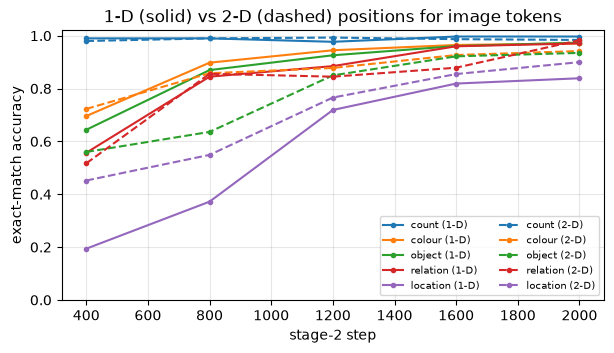

step   400: location 1-D 0.194   2-D 0.452
step   800: location 1-D 0.372   2-D 0.549
step  1200: location 1-D 0.719   2-D 0.766
step  1600: location 1-D 0.819   2-D 0.855
step  2000: location 1-D 0.839   2-D 0.900


In [10]:
import copy

set_seed(0)
lm_2d = copy.deepcopy(vlm.lm)
lm_2d.load_state_dict(lm_text_only)                                   # same text-only LM as before stage 1
vlm_1d = vlm
vlm = TinyVLM(vision, lm_2d, d_vision=128, pos2d=True).to(dev)         # same frozen vision tower
for p in vlm.vision.parameters():
    p.requires_grad = False
for p in vlm.lm.parameters():
    p.requires_grad = False
fit(cap_items, list(vlm.projector.parameters()) + [vlm.row_emb.weight, vlm.col_emb.weight], 600, 1e-3)   # stage 1
for p in vlm.lm.parameters():
    p.requires_grad = True
curve_2d = stage2(list(vlm.projector.parameters()) + [vlm.row_emb.weight, vlm.col_emb.weight] + list(vlm.lm.parameters()))
plot_curves([("1-D", curve_1d), ("2-D", curve_2d)], "1-D (solid) vs 2-D (dashed) positions for image tokens")
for (s1, a1), (_, a2) in zip(curve_1d, curve_2d):
    print(f"step {s1:5d}: location 1-D {a1['location']:.3f}   2-D {a2['location']:.3f}")

With 2-D positions, location is learned faster; the other skills are essentially unchanged. (One seed and
a small model: treat the size of the gap with caution — exercise 3 asks you to repeat it with other seeds.)
The lesson transfers to VLAs: *how image tokens are positioned* decides how easily the backbone can say
where things are — and for a manipulator, where things are is the whole task.

## 8. Where does the answer come from?
Attention of the position that generates the answer (`<sep>`) to the 64 image tokens, last layer,
averaged over heads, displayed on the 8×8 patch grid.

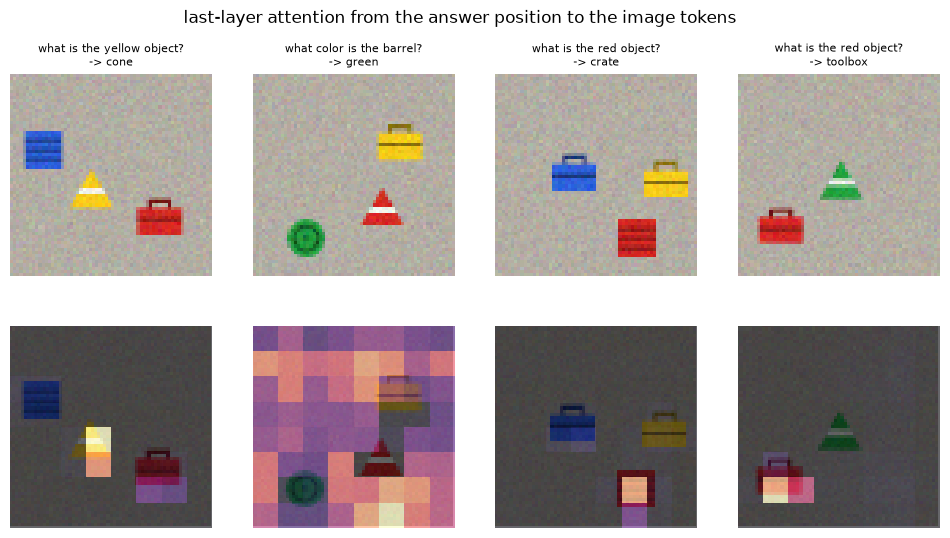

In [11]:
fig, axs = plt.subplots(2, 4, figsize=(12, 6))
two = [x for x in eval_set if len(sc[x[0]].objects) >= 2 and qtype(x[1]) in ("colour", "object")][:4]
for col, (i, q, a) in enumerate(two):
    with torch.no_grad():
        vlm(X[[i]].to(dev), torch.tensor([prompt_ids(q)], device=dev))
    w = vlm.lm.blocks[-1].attn.last_weights[0, :, -1, :64].mean(0).reshape(8, 8).cpu()   # (8, 8)
    axs[0, col].imshow(im[i]); axs[0, col].set_title(f"{q}\n-> {answer([i], [q])[0]}", fontsize=8)
    axs[1, col].imshow(im[i]); axs[1, col].imshow(w, cmap="magma", alpha=0.6, extent=(0, 64, 64, 0))
for a_ in axs.flat:
    a_.axis("off")
plt.suptitle("last-layer attention from the answer position to the image tokens")
plt.show()

## 9. Hallucination
Ask about objects that are *not* in the scene. The model was never shown a question without an answer
in the image, so it has no way to say "there is none".

In [12]:
absent = []
for i in range(N_TRAIN, N_TRAIN + 400):
    missing = [k for k in scenes.KINDS if k not in {o.kind for o in sc[i].objects}]
    absent.append((i, f"what color is the {missing[0]}?"))
replies = answer([i for i, _ in absent], [q for _, q in absent])
print("answers to questions about absent objects:", dict(zip(*np.unique(replies, return_counts=True))))
for (i, q), r in list(zip(absent, replies))[:3]:
    print(f"  scene: {caps[i]!r:45} Q: {q!r:30} A: {r!r}")

answers to questions about absent objects: {np.str_('blue'): np.int64(70), np.str_('green'): np.int64(98), np.str_('red'): np.int64(100), np.str_('yellow'): np.int64(132)}
  scene: 'a yellow barrel below a yellow crate'        Q: 'what color is the toolbox?'   A: 'yellow'
  scene: 'a yellow cone, a yellow toolbox and a green crate' Q: 'what color is the barrel?'    A: 'green'
  scene: 'a blue barrel, a blue cone and a green barrel' Q: 'what color is the toolbox?'   A: 'blue'


Every question gets a confident colour. The training data never contained a question whose answer is
"there is no cone", so the model never learned that answer exists. The same thing happens in large VLMs,
for the same reason; for a robot that will act on the answer, this is the most dangerous failure mode in
this chapter (book 5.4).

## 10. A real small VLM: SmolVLM-256M
SigLIP-B/16 vision tower at 512×512 (1024 patches) → **pixel shuffle** with factor 4 (16 neighbouring
patch tokens concatenated into one token of width 16·768 = 12 288) → linear projection to the LM width 576
→ a 135M SmolLM2-style language model. Images larger than 512 px are **split** into 512-px tiles plus a
downscaled global view (book 5.3).

In [13]:
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor

NAME = "HuggingFaceTB/SmolVLM-256M-Instruct"
proc = AutoProcessor.from_pretrained(NAME)
dtype = torch.bfloat16 if dev.type == "cuda" else torch.float32
smol = AutoModelForImageTextToText.from_pretrained(NAME, dtype=dtype).to(dev).eval()
for name, part in [("vision tower", smol.model.vision_model), ("connector", smol.model.connector),
                   ("language model", smol.model.text_model), ("LM head", smol.lm_head)]:
    print(f"{name:15} {sum(p.numel() for p in part.parameters()) / 1e6:6.1f} M parameters")
print("connector:", smol.model.connector.modality_projection.proj)
print("pixel-shuffle factor:", smol.config.scale_factor, "-> 1024 patches /", smol.config.scale_factor ** 2,
      "=", 1024 // smol.config.scale_factor ** 2, "tokens per 512px image")

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

vision tower      86.4 M parameters
connector          7.1 M parameters
language model   134.6 M parameters
LM head           28.4 M parameters
connector: Linear(in_features=12288, out_features=576, bias=False)
pixel-shuffle factor: 4 -> 1024 patches / 16 = 64 tokens per 512px image


**Pixel shuffle, by hand.** The connector's input is the vision tower's 32×32 grid of 768-d tokens,
rearranged so that every 4×4 block of neighbours becomes one token. We reproduce it and check against the
library.

In [14]:
def pixel_shuffle(x, r):
    """x: (B, N, d) on a square grid -> (B, N / r^2, d * r^2), each output token = an r x r block of inputs."""
    B, N, d = x.shape
    g = int(N ** 0.5)
    x = x.reshape(B, g // r, r, g // r, r, d)            # (B, gy, ry, gx, rx, d)
    x = x.permute(0, 1, 3, 2, 4, 5)                      # (B, gy, gx, ry, rx, d)
    return x.reshape(B, (g // r) ** 2, r * r * d)


demo_scene = scenes.random_scene(random.Random(4), n_objects=3)
img = Image.fromarray(scenes.render(demo_scene, 512, size=0.2))
msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": "Describe the objects in this image and their colors."}]}]
prompt = proc.apply_chat_template(msgs, add_generation_prompt=True)
print(repr(prompt))
inp = proc(text=prompt, images=[img], return_tensors="pt", do_image_splitting=False).to(dev)
with torch.no_grad():
    patches = smol.model.vision_model(pixel_values=inp.pixel_values[0].to(dtype)).last_hidden_state   # (1, 1024, 768)
    ours = smol.model.connector.modality_projection(pixel_shuffle(patches, 4))                       # (1, 64, 576)
    theirs = smol.model.connector(patches)
print("vision tokens", tuple(patches.shape), "-> shuffled", tuple(pixel_shuffle(patches, 4).shape),
      "-> image tokens", tuple(ours.shape), "| max diff vs library:", (ours - theirs).abs().max().item())
# (If the library's ordering ever differs from ours, the difference is a permutation of the 16 blocks.)

'<|im_start|>User:<image>Describe the objects in this image and their colors.<end_of_utterance>\nAssistant:'


vision tokens (1, 1024, 768) -> shuffled (1, 64, 12288) -> image tokens (1, 64, 576) | max diff vs library: 0.0


**Image splitting changes the token count — and the answer.** Our render is 512×512. With splitting on, the
processor first upsamples it (longest edge 2048) and cuts 4×4 tiles plus a global view.

In [15]:
for split in [False, True]:
    inp = proc(text=prompt, images=[img], return_tensors="pt", do_image_splitting=split).to(dev)
    n_img = int((inp.input_ids == smol.config.image_token_id).sum())
    t0 = time.time()
    with torch.no_grad():
        out = smol.generate(**inp, max_new_tokens=50, do_sample=False)
    text = proc.batch_decode(out[:, inp.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()
    print(f"splitting={split}: {inp.pixel_values.shape[1]} image(s), {n_img} image tokens, "
          f"sequence {inp.input_ids.shape[1]} tokens, {time.time() - t0:.1f} s\n   -> {text!r}\n")
print("ground truth:", scenes.caption(demo_scene))

splitting=False: 1 image(s), 64 image tokens, sequence 85 tokens, 0.6 s
   -> 'The image contains three objects: a red rectangle, a blue rectangle, and a yellow rectangle. The objects are placed on a grid of light gray tiles. The tiles are arranged in a grid pattern, with each tile having a different color. The tiles'



splitting=True: 17 image(s), 1088 image tokens, sequence 1145 tokens, 1.1 s
   -> 'The image contains a grid of squares on a light gray background. The grid is divided into four rows and three columns, with each row and column containing squares of equal size. The squares are arranged in a horizontal line, with each square occupying a single'

ground truth: a red crate, a yellow crate and a blue toolbox


Without splitting the model sees 64 image tokens and gets the colours roughly right. With splitting it
processes 17× more image tokens — 17× the prefill compute — for an image that contained no extra
detail, and its description gets *worse*: each 512-px tile of the upsampled image shows a featureless patch
of floor. Token budgets are a design decision with consequences for both latency and correctness (book 3.4
and 5.3).

**Spatial questions.** Small VLMs are weak at exactly what a manipulator needs:

In [16]:
for q in ["Which object is on the left side of the image?", "Is the red object above or below the blue object?",
          "How many objects are there?"]:
    m_ = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": q}]}]
    inp = proc(text=proc.apply_chat_template(m_, add_generation_prompt=True), images=[img], return_tensors="pt",
               do_image_splitting=False).to(dev)
    with torch.no_grad():
        out = smol.generate(**inp, max_new_tokens=30, do_sample=False)
    print(f"{q!r:55} -> {proc.batch_decode(out[:, inp.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()!r}")
print("objects (x, y):", [(o.color, o.kind, round(o.x, 2), round(o.y, 2)) for o in demo_scene.objects])

'Which object is on the left side of the image?'        -> 'There is a red object on the left side of the image.'


'Is the red object above or below the blue object?'     -> 'Above.'


'How many objects are there?'                           -> '3'
objects (x, y): [('yellow', 'crate', 0.65, 0.49), ('red', 'crate', 0.21, 0.16), ('blue', 'toolbox', 0.84, 0.19)]


## Exercises
1. Skip stage 1 and go straight to stage 2. Do the learning curves change?
2. Replace the MLP projector by a single linear layer (LLaVA-1.0), then by a 16-query cross-attention
   resampler (book 4.3) that reduces 64 image tokens to 16. Compare the per-skill curves and the prefill cost.
3. Repeat §7 with three seeds. Is the 2-D advantage on location larger than the seed-to-seed spread?
4. Unfreeze the vision tower in stage 2 with a learning rate 3× smaller than the LM's (the usual VLA recipe,
   book 3.4). Which skills improve?
5. Add "unanswerable" training examples ("what color is the cone?" → "there is no cone"; extend the
   vocabulary). Does hallucination disappear? Do other answers suffer?
6. Robotics: give the tiny VLM a question "where should the gripper go?" answered with one of nine regions.
   What is missing between that answer and a motor command? (This is the bridge to Part III.)